# Step 13 — learning curve: does NHANES LOCO still gain from more training people?

Step 11 added 10,518 KNHANES people to the training data and the NHANES AUROC did not move. Either Korean data is not useful, or more people of any kind no longer help. This notebook tests the second explanation using NHANES only: train on a random fraction of the training cycles and see how AUROC changes with the number of people.

**Design:**
- Leave-one-cycle-out as in step 1. The test set is always the whole held-out cycle; only the training cycles are subsampled.
- Fractions 10%, 25%, 50%, 75% and 100% of the training people, drawn within each training cycle (so the mix of cycles stays the same), 3 random draws per fraction below 100%.
- Two feature sets: all 317 features (step 1, the main model) and k114 (step 9, the setting of step 11).
- Elastic net and XGBoost.

**Hyper-parameters are fixed** to the ones step 1 / step 9 k114 chose for each test cycle by inner LOCO (for XGBoost including the number of trees); there is no tuning per fraction, which would cost about 50 times more. These values were chosen for 100% of the data, so the small fractions are slightly handicapped. That makes the curve, if anything, steeper than with retuning: a flat curve is then a safe conclusion, a rising one could be partly an artefact of the tuning. At 100% the result is the step 1 / step 9 fit itself and reproduces their AUROC.

**Reading:** the gain from 75% to 100% (about +7,000 people) is the size of change the 10,518 Korean people in step 11 could at most have brought if they were as informative as NHANES people.

**Output:** `$NHANES_WORK/modeling/step13_learning_curve/metrics.csv`. `RUN = True` recomputes (about an hour on 6 threads, CPU only); `RUN = False` only reads the saved results.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS  # noqa: E402

RUN = False  # True: recompute and overwrite $NHANES_WORK/modeling/step13_learning_curve
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
OUT = RESULTS / "step13_learning_curve"
FRACTIONS = [0.1, 0.25, 0.5, 0.75, 1.0]
SEEDS = [0, 1, 2]
SETS = {"317 features": RESULTS / "step1", "k114": RESULTS / "step9_knhanes_features" / "k114"}
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}

## Run

In [2]:
if RUN:
    from joblib import Parallel, delayed
    from sklearn.metrics import roc_auc_score

    from nhanes.loco import FEAT, NOT_FEATURES, fit_logreg, fit_xgb, logreg_matrix
    from nhanes.paths import THREADS

    OUT.mkdir(parents=True, exist_ok=True)
    mapping = pd.read_csv(ROOT / "docs" / "knhanes_mapping.csv")
    k114 = list(mapping.feature[mapping.years == "both"])
    full = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    all_feats = [c for c in full if c not in NOT_FEATURES]
    feats = {"317 features": all_feats, "k114": k114}  # column order as in steps 1 / 9 (it matters for XGBoost)
    print({fs: len(f) for fs, f in feats.items()})
    cycles = sorted(full.cycle.unique())

    def draws():
        for fs in SETS:
            for test_c in cycles:
                for frac in FRACTIONS:
                    for seed in (SEEDS if frac < 1 else [0]):
                        yield fs, test_c, frac, seed

    def subsample(test_c, frac, seed):
        tr = full[full.cycle != test_c]
        if frac < 1:
            tr = tr.groupby("cycle", group_keys=False).sample(frac=frac, random_state=seed)
        return tr, full[full.cycle == test_c]

    def run_logreg(fs, test_c, frac, seed, params):
        tr, te = subsample(test_c, frac, seed)
        A, B = logreg_matrix(tr[feats[fs]], te[feats[fs]], dic)
        prob = fit_logreg(A, tr.depression, params).predict_proba(B)[:, 1]
        return {"features": fs, "model": "logreg", "test_cycle": test_c, "fraction": frac, "seed": seed,
                "n_train": len(tr), "auroc": roc_auc_score(te.depression, prob)}

    chosen = {fs: json.loads((d / "chosen_params.json").read_text()) for fs, d in SETS.items()}
    pick = lambda fs, m, c: {k: v for k, v in chosen[fs][f"{m}|{c}"].items() if k != "inner_auroc"}  # noqa: E731

    t0 = time.time()
    rows = Parallel(n_jobs=THREADS, verbose=5)(
        delayed(run_logreg)(fs, c, f, s, pick(fs, "logreg", c)) for fs, c, f, s in draws())
    print(f"elastic net: {(time.time() - t0) / 60:.1f} min", flush=True)

    t0 = time.time()
    for fs, c, f, s in draws():
        tr, te = subsample(c, f, s)
        p = pick(fs, "xgboost", c)
        n = p.pop("n_estimators")
        m = fit_xgb(tr[feats[fs]], tr.depression, None, None, p, n_estimators=n)
        rows.append({"features": fs, "model": "xgboost", "test_cycle": c, "fraction": f, "seed": s,
                     "n_train": len(tr), "auroc": roc_auc_score(te.depression, m.predict_proba(te[feats[fs]])[:, 1])})
    print(f"XGBoost: {(time.time() - t0) / 60:.1f} min", flush=True)
    pd.DataFrame(rows).to_csv(OUT / "metrics.csv", index=False)

## Results

Check first: at 100% the AUROC per test cycle should equal step 1 / step 9 k114.

In [3]:
met = pd.read_csv(OUT / "metrics.csv")
ref = pd.concat([pd.read_csv(d / "metrics.csv").assign(features=fs) for fs, d in SETS.items()])
chk = met[met.fraction == 1].merge(ref[["features", "model", "test_cycle", "auroc"]],
                                   on=["features", "model", "test_cycle"], suffixes=("", "_ref"))
print("largest |difference| from the original run at 100%:", f"{(chk.auroc - chk.auroc_ref).abs().max():.4f}")

largest |difference| from the original run at 100%: 0.0000


Mean AUROC over the 7 test cycles (and, below 100%, over the 3 draws). `n_train` is the mean number of training people.

In [4]:
per_cycle = met.groupby(["features", "model", "fraction", "test_cycle"], as_index=False)[["auroc", "n_train"]].mean()
curve = per_cycle.groupby(["features", "model", "fraction"]).agg(
    n_train=("n_train", "mean"), auroc=("auroc", "mean"), sd_over_cycles=("auroc", "std"))
curve["n_train"] = curve.n_train.round(-1).astype(int)
wide = curve.auroc.unstack("fraction")
wide.columns = [f"{int(f * 100)}%" for f in wide.columns]
display(curve.round(4))
display(wide.rename(index=NAMES, level="model").round(3))

n_train   auroc  sd_over_cycles
features     model   fraction                                 
317 features logreg  0.10         2870  0.8342          0.0104
                     0.25         7180  0.8580          0.0091
                     0.50        14360  0.8683          0.0111
                     0.75        21530  0.8715          0.0112
                     1.00        28710  0.8735          0.0108
             xgboost 0.10         2870  0.8355          0.0144
                     0.25         7180  0.8573          0.0101
                     0.50        14360  0.8664          0.0103
                     0.75        21530  0.8702          0.0107
                     1.00        28710  0.8711          0.0097
k114         logreg  0.10         2870  0.8005          0.0162
                     0.25         7180  0.8222          0.0128
                     0.50        14360  0.8303          0.0137
                     0.75        21530  0.8327          0.0131
                     1.00        28710  0.8341          0.0128
             xgboost 0.10         2870  0.8007          0.0186
                     0.25         7180  0.8198          0.0115
                     0.50        14360  0.8281          0.0110
                     0.75        21530  0.8318          0.0105
                     1.00        28710  0.8334          0.0110

10%    25%    50%    75%   100%
features     model                                         
317 features elastic net  0.834  0.858  0.868  0.872  0.874
             XGBoost      0.835  0.857  0.866  0.870  0.871
k114         elastic net  0.801  0.822  0.830  0.833  0.834
             XGBoost      0.801  0.820  0.828  0.832  0.833

Gain per step, paired by test cycle (the same 7 test sets, so cycle-to-cycle differences cancel). "≈ step 11" is the step from 75% to 100% of the training people, about the size of the 10,518 KNHANES people added in step 11.

In [5]:
p = per_cycle.pivot_table(index=["features", "model", "test_cycle"], columns="fraction", values="auroc")
steps = pd.DataFrame({"10% → 25%": p[0.25] - p[0.1], "25% → 50%": p[0.5] - p[0.25],
                      "50% → 100%": p[1.0] - p[0.5], "75% → 100% (≈ step 11)": p[1.0] - p[0.75]})
gain = steps.groupby(level=["features", "model"]).agg(["mean", "min", "max"])
display(gain.rename(index=NAMES, level="model").round(4))

10% → 25%                 25% → 50%                  \
                              mean     min     max      mean     min     max   
features     model                                                             
317 features elastic net    0.0238  0.0183  0.0320    0.0103  0.0054  0.0144   
             XGBoost        0.0219  0.0111  0.0325    0.0091  0.0058  0.0119   
k114         elastic net    0.0217  0.0128  0.0291    0.0082  0.0046  0.0110   
             XGBoost        0.0191  0.0086  0.0320    0.0083  0.0064  0.0099   

                         50% → 100%                 75% → 100% (≈ step 11)  \
                               mean     min     max                   mean   
features     model                                                           
317 features elastic net     0.0052  0.0043  0.0065                 0.0020   
             XGBoost         0.0047  0.0017  0.0100                 0.0009   
k114         elastic net     0.0038  0.0015  0.0057                 0.0014   
             XGBoost         0.0053  0.0037  0.0093                 0.0016   

                                          
                             min     max  
features     model                        
317 features elastic net  0.0010  0.0029  
             XGBoost     -0.0005  0.0045  
k114         elastic net -0.0002  0.0025  
             XGBoost      0.0003  0.0035

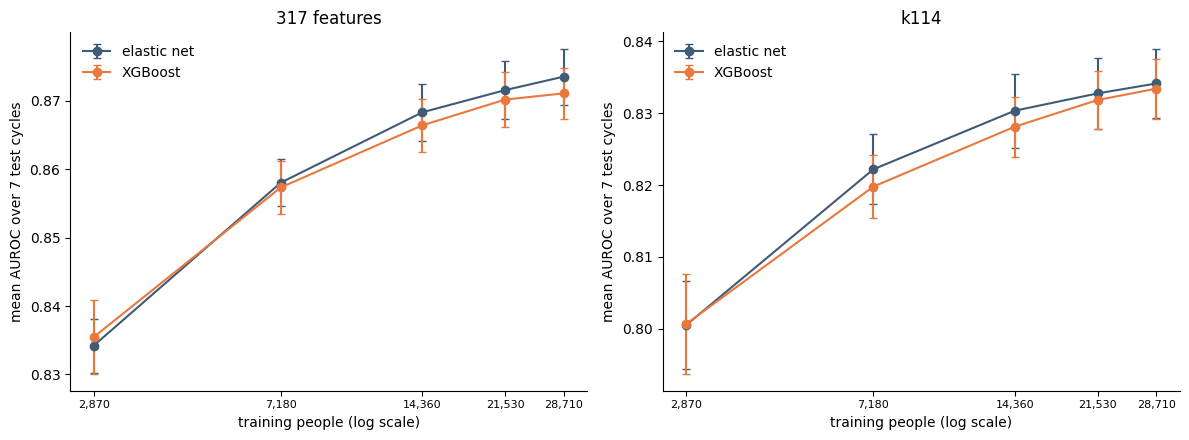

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for ax, fs in zip(axes, SETS):
    for model, color in zip(NAMES, ["#405B76", "#E9783D"]):
        c = curve.loc[(fs, model)]
        ax.errorbar(c.n_train, c.auroc, yerr=c.sd_over_cycles / np.sqrt(7), fmt="o-", color=color,
                    capsize=3, label=NAMES[model])
    ax.set_xscale("log")
    ax.set_xticks(curve.loc[(fs, "logreg")].n_train, [f"{n:,}" for n in curve.loc[(fs, "logreg")].n_train],
                  fontsize=8)
    ax.minorticks_off()
    ax.set_xlabel("training people (log scale)")
    ax.set_ylabel("mean AUROC over 7 test cycles")
    ax.set_title(fs)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plots.show()

## Conclusions

- **The check passes:** at 100% every test cycle reproduces step 1 / step 9 k114 exactly.
- **The curve is flattening.** Each doubling of the training people brings about half as much as the one before. Mean AUROC (elastic net / XGBoost), all 317 features: 0.834 / 0.835 at 10% (2,870 people), 0.868 / 0.866 at 50%, 0.874 / 0.871 at 100% (28,710). k114: 0.801 / 0.801, 0.830 / 0.828, 0.834 / 0.833.
- **The last 25% (+7,180 people) is worth +0.001 to +0.002**, paired by test cycle (317 features 0.0020 / 0.0009, k114 0.0014 / 0.0016). That is about a tenth of the spread between test cycles (sd about 0.011).
- **What this means for step 11:** the 10,518 KNHANES people are 37% more training people. If they were as informative as NHANES people, the gain would be roughly +0.002. Step 11 observed +0.0001 / −0.0005. So Korean people helped less than NHANES people would have, but even the best case is a gain that could hardly be seen against the noise between cycles.
- **The same holds for the full model:** adding Korean people to the 317-feature model (with the 203 features they lack left missing) could at best bring about the same +0.002, so it is not worth running.
- **Features matter more than people:** going from k114 to 317 features adds 0.04 AUROC at every sample size, about 20 times more than the last 7,000 people.